# Volatilité des marchés financiers, contagion internationale et politique monétaire (2000–2025)

**Projet Python — ENSAE (2026)**  
**Auteurs :** Romain Mirat, Alexandre Lim de Mongolfier, Albéric Pungier

---

### Sommaire du rapport
* **Partie A — Dynamique des marchés financiers, volatilité et transmission internationale des chocs** (`src/marches.py`, `src/transmission.py`)
* **Partie B — Annonces de politique monétaire de la BCE et réaction des marchés européens** (`src/bce.py`)
* **Partie C — Décisions de la Réserve fédérale (Fed) et transmission globale** (`src/fed.py`)

In [2]:
import warnings
warnings.filterwarnings("ignore")

from IPython.display import display
from src import marches, transmission

## Partie A — Dynamique des marchés financiers, volatilité et transmission internationale

## 1. Caractérisation statistique et volatilité des grands marchés mondiaux

### Données et méthodologie
L'étude couvre la période du 1er janvier 2000 au 31 décembre 2025 pour trois grands indices boursiers représentatifs des principales zones horaires mondiales — le **S&P 500** (New York), le **CAC 40** (Paris) et le **Nikkei 225** (Tokyo) — ainsi que l'indice **VIX**, qui mesure la volatilité implicite à 30 jours anticipée sur les options du S&P 500.

À partir des rendements logarithmiques journaliers $r_t = \ln(C_t / C_{t-1})$ et des cotations intrajournalières (ouverture, plus haut, plus bas, clôture), nous estimons la volatilité réalisée journalière à l'aide de deux estimateurs basés sur l'amplitude des prix :
* **L'estimateur de Parkinson (1980)**, fondé sur l'écart extrême entre le plus haut ($H_t$) et le plus bas ($L_t$) de la séance :
  $$\sigma_{\text{Parkinson}, t} = \sqrt{\frac{1}{4 \ln 2} \left(\ln \frac{H_t}{L_t}\right)^2}$$
* **L'estimateur de Garman-Klass (1980)**, utilisé comme contrôle de robustesse en intégrant également l'écart entre ouverture et clôture :
  $$\sigma_{\text{GK}, t} = \sqrt{0,5 \left(\ln \frac{H_t}{L_t}\right)^2 - (2 \ln 2 - 1) \left(\ln \frac{C_t}{O_t}\right)^2}$$

### Faits stylisés des rendements et de la volatilité
L'analyse descriptive met en évidence les propriétés classiques des séries financières :
* **Queues épaisses (*leptokurticité*) et asymétrie négative :** tous les indices actions présentent une asymétrie (*skewness*) négative (entre $-0,22$ pour le CAC 40 et $-0,41$ pour le Nikkei) et un excès de kurtosis très élevé ($10,63$ pour le S&P 500, $7,24$ pour le Nikkei et $6,65$ pour le CAC 40), traduisant une fréquence des krachs extrêmes bien supérieure à celle d'une loi normale. Les pires séances atteignent $-12,77\%$ sur le S&P 500 (16 mars 2020), $-13,10\%$ sur le CAC 40 (12 mars 2020) et $-13,23\%$ sur le Nikkei (5 août 2024).
* **Cohérence des estimateurs de volatilité :** la volatilité moyenne de Parkinson s'établit à $0,78\%$ par jour sur le S&P 500, $0,80\%$ sur le Nikkei et $0,89\%$ sur le CAC 40. Elle est très fortement corrélée à l'estimateur de Garman-Klass ($r > 0,93$ sur l'ensemble des indices), confirmant la robustesse de la mesure.
* **Regroupement de la volatilité (*volatility clustering*) :** les épisodes de forte turbulence surviennent simultanément sur les trois places financières, notamment lors de la crise financière de 2008–2009 (volatilité lissée sur 20 jours dépassant $4\%$ et VIX au-dessus de 80) et du krach du Covid-19 en mars 2020 (volatilité supérieure à $3\%$ et VIX supérieur à 80). Le resserrement monétaire de 2022 génère une tension plus modérée mais persistante sur l'ensemble de l'année.
* **Renforcement apparent des corrélations en crise :** la corrélation contemporaine entre le S&P 500 et le CAC 40 passe de $0,49$ avant crise (2000–2007) à $0,59$ en 2008–2009 et $0,75$ au printemps 2020, tandis que le VIX demeure fortement corrélé négativement au S&P 500 (jusqu'à $-0,86$ en 2008–2009). En revanche, la corrélation le même jour entre le S&P 500 et le Nikkei reste faible ($0,11$ à $0,37$) en raison du décalage horaire entre Tokyo et New York.

,rendement_moyen_pct,ecart_type_pct,skewness,kurtosis,q01_pct,q99_pct,pire_journee,meilleure_journee,vol_parkinson_moy_pct,vol_gk_moy_pct,corr_parkinson_gk
marche,,,,,,,,,,,
SP500,0.0237,1.222,-0.35,10.63,-3.48,3.30,-12.77% (2020-03-16),+10.96% (2008-10-13),0.777,0.740,0.9382
CAC40,0.0048,1.374,-0.22,6.65,-4.04,3.52,-13.10% (2020-03-12),+10.59% (2008-10-13),0.893,0.889,0.9508
NIKKEI,0.0153,1.463,-0.41,7.24,-4.02,3.53,-13.23% (2024-08-05),+13.23% (2008-10-14),0.798,0.773,0.9349
VIX,-0.0074,7.157,1.02,6.88,-16.69,21.62,-44.24% (2025-04-09),+76.82% (2018-02-05),5.173,5.156,0.9539


(<Figure size 1200x700 with 2 Axes>, <Figure size 1500x400 with 5 Axes>)

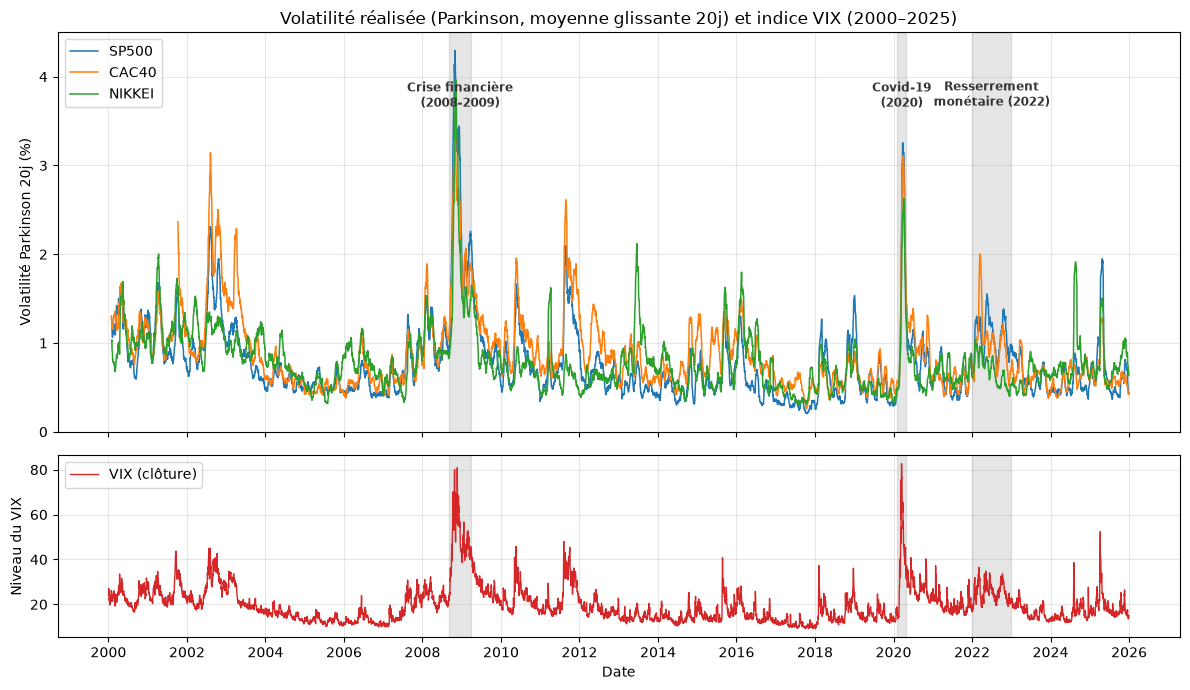

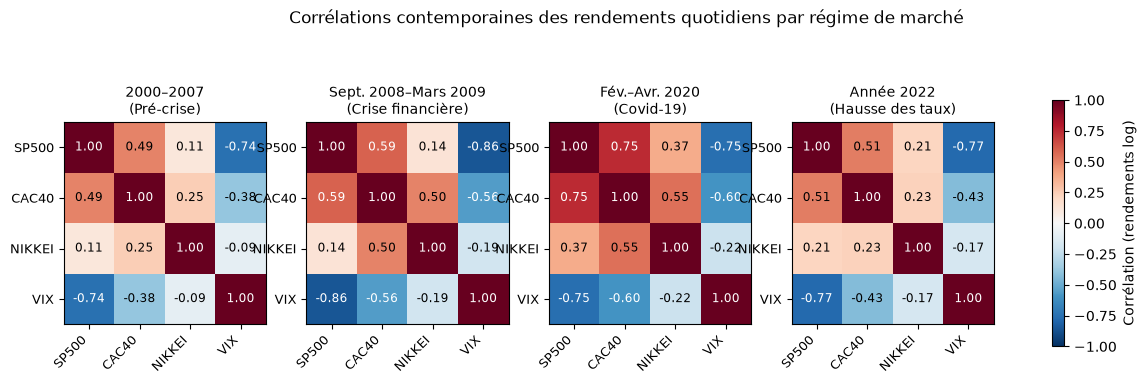

In [4]:
res_marches = marches.analyse()
display(res_marches)
marches.figure()

## 2. Transmission internationale des chocs et contagion financière

Au-delà de la dynamique propre à chaque indice, l'analyse des corrélations croisées met en évidence la hiérarchie temporelle et la forte interdépendance des places financières mondiales entre New York, Paris et Tokyo :

* **Effet de décalage horaire (*lead-lag* New York $\to$ Tokyo / Paris) :** Le chevauchement des horaires de cotation structure directement la diffusion des chocs. Le CAC 40, qui partage une partie de sa séance avec Wall Street, présente une corrélation contemporaine élevée avec le S&P 500 ($r_t = 0{,}5599$), contre $r_{t+1} = 0{,}2225$ le lendemain ($\beta_{t+1} = 0{,}2500$, $R^2 = 4{,}95\,\%$, mais $R^2 = 14{,}51\,\%$ sur le rendement *overnight* à l'ouverture). À l'inverse, Tokyo étant fermé pendant la séance américaine, le Nikkei 225 affiche une corrélation faible le jour même ($r_t = 0{,}1465$) mais absorbe massivement le choc américain dès le lendemain ($r_{t+1} = 0{,}4793$, $\beta_{t+1} = 0{,}5722$, $p < 10^{-70}$), le S&P 500 expliquant $22{,}97\,\%$ de la variance journalière et $43{,}61\,\%$ du rendement *overnight* de l'indice japonais.
* **Asymétrie de transmission (baisses vs hausses) :** La transmission des chocs américains est statistiquement asymétrique au seuil de $5\,\%$. Les séances négatives du S&P 500 se propagent avec une sensibilité significativement plus forte que les séances positives, aussi bien vers le CAC 40 ($\beta_{\text{baisses}} = 0{,}2850$ contre $\beta_{\text{hausses}} = 0{,}2117$, soit un écart de $+0{,}0733$, $t = 2{,}01$, $p = 0{,}0442$) que vers le Nikkei 225 ($\beta_{\text{baisses}} = 0{,}6014$ contre $\beta_{\text{hausses}} = 0{,}5258$, soit un écart de $+0{,}0755$, $t = 2{,}12$, $p = 0{,}0340$), traduisant une amplification de l'aversion au risque en phase baissière.
* **Correction du biais de volatilité (Forbes et Rigobon, 2002) :** En période de crise, la hausse brutale de la variance du S&P 500 (multipliée par un facteur allant de $3{,}78$ en 2022 à $27{,}17$ lors du choc Covid-19 de 2020) gonfle mécaniquement les corrélations brutes — qui grimpent par exemple de $0{,}5070$ en période calme (2003–2007, hors bulle Internet) à $0{,}5905$ (2008–2009) et $0{,}7480$ (2020) pour le CAC 40, ou de $0{,}4105$ à $0{,}6605$ (2008–2009) pour le Nikkei. Une fois corrigées de ce biais d'hétéroscédasticité, les corrélations ajustées de Forbes-Rigobon retombent systématiquement en dessous de leur niveau de période calme (entre $0{,}0631$ et $0{,}3763$ selon les crises et les indices). La hausse apparente des co-mouvements en crise reflète donc avant tout l'ampleur des chocs globaux et l'interdépendance structurelle des marchés plutôt qu'une rupture de contagion pure.

,corr_meme_jour_t,corr_lendemain_t1,beta_close_t1,p_val_close_t1,r2_close_t1_pct,beta_overnight_t1,r2_overnight_t1_pct
marche_cible,,,,,,,
CAC40,0.5599,0.2225,0.2500,2.590000e-73,4.95,0.2500,14.51
NIKKEI,0.1465,0.4793,0.5722,0.000000e+00,22.97,0.3992,43.61


,beta_baisses,corr_baisses,beta_hausses,corr_hausses,ecart_beta_b_moins_h,t_stat_asymetrie,p_valeur_asymetrie
marche_cible,,,,,,,
CAC40,0.2850,0.1908,0.2117,0.1442,0.0733,2.01,0.0442
NIKKEI,0.6014,0.3983,0.5258,0.3513,0.0755,2.12,0.0340


,paire,periode_crise,ratio_variance,corr_calme,corr_brute_crise,corr_forbes_rigobon,ecart_fr_vs_calme
0,SP500 -> CAC40,Crise financière (2008-2009),20.70,0.5070,0.5905,0.1588,-0.3482
1,SP500 -> CAC40,Covid-19 (Fév.-Avr. 2020),25.85,0.5070,0.7480,0.2164,-0.2906
2,SP500 -> CAC40,Resserrement monétaire (2022),3.87,0.5070,0.5124,0.2902,-0.2168
3,SP500 -> NIKKEI_t1,Crise financière (2008-2009),21.03,0.4105,0.6605,0.1884,-0.2221
4,SP500 -> NIKKEI_t1,Covid-19 (Fév.-Avr. 2020),27.17,0.4105,0.3128,0.0631,-0.3474
5,SP500 -> NIKKEI_t1,Resserrement monétaire (2022),3.78,0.4105,0.6199,0.3763,-0.0342


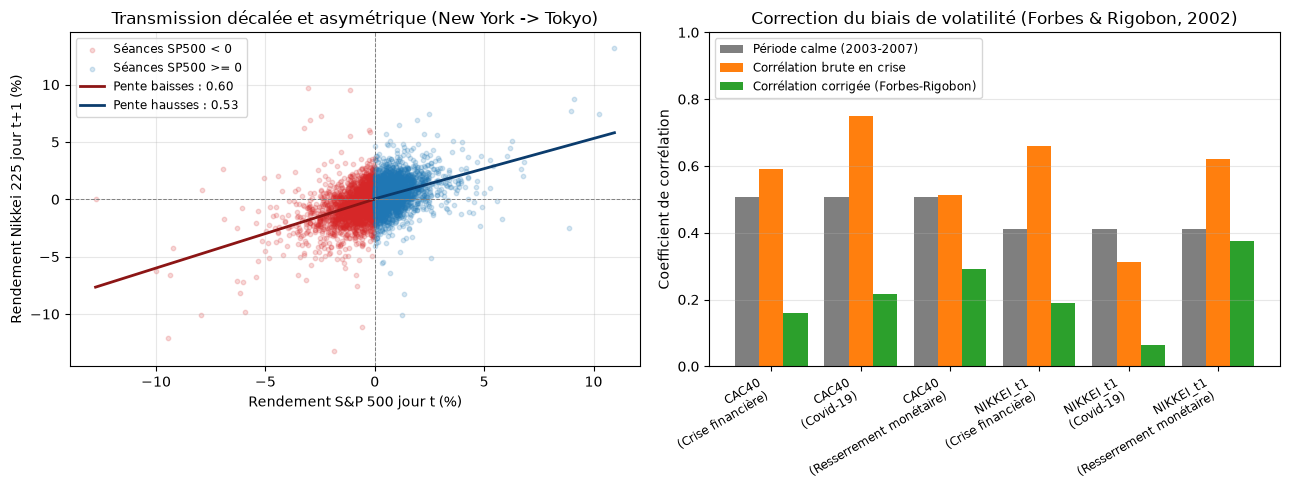

In [8]:
res_trans = transmission.analyse()
display(res_trans["decalage_horaire"])
display(res_trans["asymetrie"])
display(res_trans["forbes_rigobon"])
transmission.figure()

---

## Partie B — Annonces de politique monétaire de la BCE et réaction des marchés européens

*Emplacement réservé pour l'intégration de `textes/bce.md` et `src/bce.py`.*

---

## Partie C — Décisions de la Réserve fédérale (Fed) et transmission globale

*Emplacement réservé pour l'intégration de `textes/fed.md` et `src/fed.py`.*